In [ ]:
from google.colab import drive
drive.mount('/content/drive')

PACK = '/content/drive/MyDrive/DLP_A3/DLP_Assignment_03'
%cd $PACK
!ls

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/DLP_A3/DLP_Assignment_03
config.yaml  DLP_Assignment_03.pdf  env_check.py  report  setup  starter  utils


In [ ]:
!pip -q install torch torchvision ultralytics segmentation-models-pytorch torchmetrics pycocotools opencv-python matplotlib pandas scikit-learn tqdm pyyaml tabulate pillow numpy
!python env_check.py

Python  : 3.13.16  (Linux-6.6.159+-x86_64-with-glibc2.39)
[  OK   ] torch                            2.11.0+cu130
[  OK   ] torchvision                      0.26.0+cu130
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
[  OK   ] ultralytics                      8.4.203
[  OK   ] segmentation_models_pytorch      0.6.0
[  OK   ] torchmetrics                     1.9.0
[  OK   ] pycocotools                      ?
[  OK   ] cv2                              4.14.0
[  OK   ] matplotlib                       3.10.0
[  OK   ] sklearn                          1.6.1
[  OK   ] pandas                           2.2.3
[  OK   ] tqdm                             4.67.3

CUDA available : True
GPU            : Tesla T4
GPU memory     : 14.6 GiB

Environment looks go

In [ ]:
!python setup/download_datasets.py --voc

[ok] PASCAL VOC 2007 ready under /content/drive/MyDrive/DLP_A3/DLP_Assignment_03/data/VOCdevkit
     Next: python setup/voc_to_yolo.py   (builds the shared detection split)

If a download stalls or a mirror 404s, see the Troubleshooting section in
README.md - there are documented fallbacks for VOC and IMDB.
--2026-11-06 06:37:13--  https://github.com/huggingface/datasets/raw/main/datasets/imdb/aclImdb_v1.tar.gz
Resolving github.com (github.com)... 20.205.243.166
Connecting to github.com (github.com)|20.205.243.166|:443... connected.
HTTP request sent, awaiting response... 404 Not Found
2026-11-06 06:37:14 ERROR 404: Not Found.



Question 1 : 1.1

In [ ]:
!python setup/voc_to_yolo.py

train images : 2000
val images   : 500
objects per class (whole set):
   person     3655
   car        948
   dog        421
   cat        266
   bicycle    284

data.yaml written to /content/drive/MyDrive/DLP_A3/DLP_Assignment_03/data/voc_yolo/data.yaml
Copy the per-class counts into your report - the class imbalance here explains
a lot about the per-class AP numbers you are about to see.


Question 1: 1.2

In [ ]:
!python starter/q1a_yolo.py --zero-shot

Ultralytics 8.4.203 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLOv8n summary (fused): 72 layers, 3,151,904 parameters, 0 gradients, 8.7 GFLOPs
val: Fast image access ✅ (ping: 0.5±0.1 ms, read: 71.2±32.7 MB/s, size: 94.3 KB)
val: Scanning /content/drive/MyDrive/DLP_A3/DLP_Assignment_03/data/voc_yolo/labels/val... 500 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 500/500 170.5it/s 2.9s
val: New cache created: /content/drive/MyDrive/DLP_A3/DLP_Assignment_03/data/voc_yolo/labels/val.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 32/32 4.9it/s 6.5s
                   all        500       1108      0.163      0.166      0.178      0.129
                person        319        702      0.813      0.829      0.887      0.645
               bicycle        121        213          0          0   0.000118   4.66e-05
                   car         76         90          0          0   8.27e-05   3.52e-0

Question 1: 1.3

In [ ]:
!python starter/q1a_yolo.py

Ultralytics 8.4.203 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/DLP_A3/DLP_Assignment_03/data/voc_yolo/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=25, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8n_ft25, nbs=

Question 1 : 1.4

In [ ]:
!python starter/q1b_faster_rcnn.py

[device] cuda | classes ['person', 'car', 'dog', 'cat', 'bicycle']
[data] train 2000 | val 500
Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth
100% 160M/160M [00:00<00:00, 193MB/s]
[params] total 41,319,661 | trainable 41,097,261
train e1:   0% 0/500 [00:00<?, ?it/s]/content/drive/MyDrive/DLP_A3/DLP_Assignment_03/starter/q1b_faster_rcnn.py:151: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  running += float(loss)
epoch 01 | loss 0.287 | mAP50 0.8517 | mAP50-95 0.5151
epoch 02 | loss 0.206 | mAP50 0.8931 | mAP50-95 0.5549
epoch 03 | loss 0.184 | mAP50 0.8832 | mAP50-95 0.5750
epoch 04 | loss 0.147 | mAP50 0.9093 | mAP50-95 0.6222
epoch 05 | loss 0.139 | mAP50 0.9072 | mAP50-

Question 1: 1.5

In [ ]:
!python starter/make_tables.py

[written] /content/drive/MyDrive/DLP_A3/DLP_Assignment_03/report/tables.md
# Results tables
Generated by starter/make_tables.py - do not hand-edit, re-run it instead.

## Q1 - object detection: YOLOv8 vs Faster R-CNN

| detector                 | weights    |   zero_shot |   epochs |   mAP50 |   mAP50_95 |   mAP_small |   mAP_large |   inference_ms_per_image |   fps |   total_params |   train_minutes |
|:-------------------------|:-----------|------------:|---------:|--------:|-----------:|------------:|------------:|-------------------------:|------:|---------------:|----------------:|
| yolov8                   | yolov8n.pt |           1 |        0 |  0.1776 |     0.1291 |    nan      |    nan      |                     4.87 | 205.3 |  nan           |             0   |
| yolov8                   | yolov8n.pt |           0 |       25 |  0.754  |     0.4975 |    nan      |    nan      |                     4.72 | 211.7 |  nan           |             7.7 |
| faster_rcnn_resnet50_fpn | n

**QUESTION 3**

In [2]:
%cd /content/drive/MyDrive/DLP_A3/DLP_Assignment_03

# 1. Extract archive directly to fast local session disk (/content/) - TAKES ~3 SECONDS!
!tar -xzf data/aclImdb.tgz -C /content/

# 2. Instantly rename the old broken Drive folder out of the way (takes 0.1 seconds!)
!mv data/aclImdb data/aclImdb_junk 2>/dev/null || true

# 3. Create the symlink pointing to local SSD
!ln -s /content/aclImdb data/aclImdb

# 4. Verify that both 'train' and 'test' are present
!ls -la data/aclImdb

/content/drive/MyDrive/DLP_A3/DLP_Assignment_03
lrw------- 1 root root 16 Nov  7 07:27 data/aclImdb -> /content/aclImdb


In [ ]:
!ls -la data/aclImdb

lrw------- 1 root root 16 Nov  6 17:04 data/aclImdb -> /content/aclImdb


Question 3: 3.1

In [5]:
!python starter/q3_rnn_lstm.py --cell rnn
!python starter/q3_rnn_lstm.py --cell lstm
!python starter/q3_rnn_lstm.py --cell gru

[device] cuda | cell rnn | max_len 200 | clip 5.0
[data] vocab 20000 | train 25000 | test 25000
[data] train length stats: {'n': 25000, 'mean_len': 159.3, 'median_len': 174, 'p90_len': 200, 'max_len_seen': 200, 'truncated_fraction': 0.4174}
[data] OOV rate on train sample: 0.0278
[params] total 2,029,698 | recurrent layer 29,440
epoch 01 | train loss 0.6809 acc 0.5672 | test loss 0.6318 acc 0.6512 | mean grad norm 0.88
epoch 02 | train loss 0.6590 acc 0.6014 | test loss 0.6441 acc 0.6369 | mean grad norm 1.11
epoch 03 | train loss 0.6016 acc 0.6847 | test loss 0.5972 acc 0.6991 | mean grad norm 1.29
epoch 04 | train loss 0.5614 acc 0.7198 | test loss 0.6009 acc 0.6980 | mean grad norm 5.15
[fig] /content/drive/MyDrive/DLP_A3/DLP_Assignment_03/runs/q3/rnn_len200_h128/curves.png
[saved] /content/drive/MyDrive/DLP_A3/DLP_Assignment_03/runs/q3/results.json

Done. Add this row to your Q3 table, then run the next cell type or length.
[device] cuda | cell lstm | max_len 200 | clip 5.0
[data] 

Question 3: 3.3

In [3]:

!python starter/q3_rnn_lstm.py --cell rnn --max-len 50
!python starter/q3_rnn_lstm.py --cell rnn --max-len 200
!python starter/q3_rnn_lstm.py --cell rnn --max-len 500


[device] cuda | cell rnn | max_len 50 | clip 5.0
[data] vocab 20000 | train 25000 | test 25000
[data] train length stats: {'n': 25000, 'mean_len': 49.8, 'median_len': 50, 'p90_len': 50, 'max_len_seen': 50, 'truncated_fraction': 0.9779}
[data] OOV rate on train sample: 0.0278
[params] total 2,029,698 | recurrent layer 29,440
epoch 01 | train loss 0.7013 acc 0.5122 | test loss 0.6923 acc 0.5253 | mean grad norm 0.80
epoch 02 | train loss 0.6875 acc 0.5470 | test loss 0.7017 acc 0.4934 | mean grad norm 0.80
epoch 03 | train loss 0.6797 acc 0.5722 | test loss 0.6948 acc 0.5926 | mean grad norm 0.91
epoch 04 | train loss 0.6722 acc 0.5845 | test loss 0.6961 acc 0.5699 | mean grad norm 1.16
[fig] /content/drive/MyDrive/DLP_A3/DLP_Assignment_03/runs/q3/rnn_len50_h128/curves.png
[saved] /content/drive/MyDrive/DLP_A3/DLP_Assignment_03/runs/q3/results.json

Done. Add this row to your Q3 table, then run the next cell type or length.
[device] cuda | cell rnn | max_len 200 | clip 5.0
[data] vocab 2

In [4]:

!python starter/q3_rnn_lstm.py --cell lstm --max-len 50
!python starter/q3_rnn_lstm.py --cell lstm --max-len 200
!python starter/q3_rnn_lstm.py --cell lstm --max-len 500

[device] cuda | cell lstm | max_len 50 | clip 5.0
[data] vocab 20000 | train 25000 | test 25000
[data] train length stats: {'n': 25000, 'mean_len': 49.8, 'median_len': 50, 'p90_len': 50, 'max_len_seen': 50, 'truncated_fraction': 0.9779}
[data] OOV rate on train sample: 0.0278
[params] total 2,118,018 | recurrent layer 117,760
epoch 01 | train loss 0.6700 acc 0.5781 | test loss 0.6196 acc 0.6678 | mean grad norm 0.39
epoch 02 | train loss 0.5461 acc 0.7292 | test loss 0.5526 acc 0.7080 | mean grad norm 0.71
epoch 03 | train loss 0.4386 acc 0.8034 | test loss 0.5184 acc 0.7404 | mean grad norm 0.82
epoch 04 | train loss 0.3557 acc 0.8501 | test loss 0.5415 acc 0.7499 | mean grad norm 0.87
[fig] /content/drive/MyDrive/DLP_A3/DLP_Assignment_03/runs/q3/lstm_len50_h128/curves.png
[saved] /content/drive/MyDrive/DLP_A3/DLP_Assignment_03/runs/q3/results.json

Done. Add this row to your Q3 table, then run the next cell type or length.
[device] cuda | cell lstm | max_len 200 | clip 5.0
[data] voc

[RNN] Plotted lengths [50, 200, 500] -> Accuracies: [59.260000000000005, 69.91000000000001, 75.33999999999999]
[LSTM] Plotted lengths [50, 200, 500] -> Accuracies: [74.99, 81.44, 84.71]


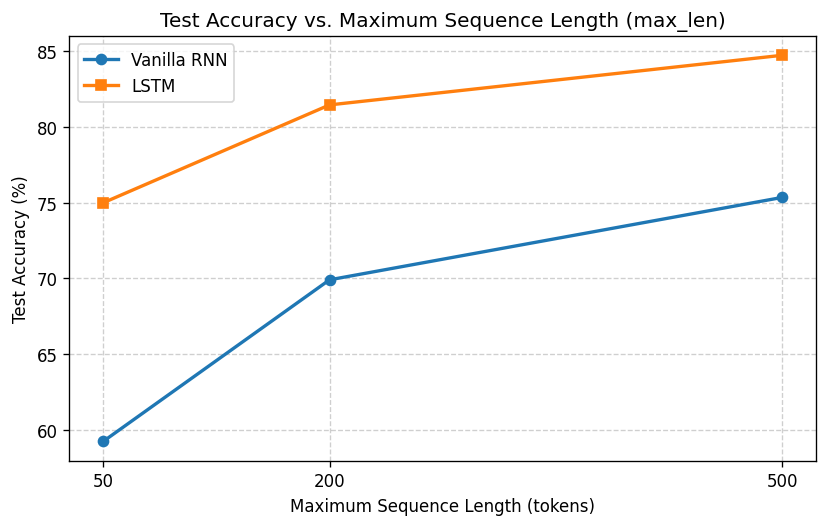

In [7]:
import json
import matplotlib.pyplot as plt
from pathlib import Path

results_file = Path("runs/q3/results.json")

if not results_file.exists():
    print(" Could not find runs/q3/results.json. Check your current working directory.")
else:
    data = json.loads(results_file.read_text())

    runs = {}
    for entry in data:
        cell = entry.get("cell")
        max_len = entry.get("max_len")
        acc = entry.get("best_test_acc")
        readout = entry.get("readout", "last")
        noclip = entry.get("clip_grad", 5.0) == 0.0


        if cell in ["rnn", "lstm"] and readout == "last" and not noclip:
            if cell not in runs:
                runs[cell] = {}
            runs[cell][max_len] = acc * 100

    plt.figure(figsize=(7, 4.5), dpi=120)

    style_map = {"rnn": ("o-", "Vanilla RNN"), "lstm": ("s-", "LSTM")}

    for cell in ["rnn", "lstm"]:
        if cell in runs:

            sorted_lens = sorted(runs[cell].keys())
            accs = [runs[cell][l] for l in sorted_lens]
            fmt, label = style_map[cell]
            plt.plot(sorted_lens, accs, fmt, linewidth=2, label=label)
            print(f"[{cell.upper()}] Plotted lengths {sorted_lens} -> Accuracies: {accs}")

    plt.title("Test Accuracy vs. Maximum Sequence Length (max_len)", fontsize=12)
    plt.xlabel("Maximum Sequence Length (tokens)", fontsize=10)
    plt.ylabel("Test Accuracy (%)", fontsize=10)
    plt.xticks([50, 200, 500])
    plt.grid(True, linestyle="--", alpha=0.6)
    plt.legend()
    plt.tight_layout()
    plt.savefig("runs/q3/q3_3_sequence_length_study.png")
    plt.show()

Question 3: 3.4

In [8]:
!python starter/q3_rnn_lstm.py --cell rnn --max-len 500 --grad-flow
!python starter/q3_rnn_lstm.py --cell lstm --max-len 500 --grad-flow

!python starter/q3_rnn_lstm.py --cell rnn --no-clip

[device] cuda | cell rnn | max_len 500 | clip 5.0
[data] vocab 20000 | train 25000 | test 25000
[data] train length stats: {'n': 25000, 'mean_len': 218.4, 'median_len': 174, 'p90_len': 458, 'max_len_seen': 500, 'truncated_fraction': 0.0806}
[data] OOV rate on train sample: 0.0278
[params] total 2,029,698 | recurrent layer 29,440
epoch 01 | train loss 0.6695 acc 0.5882 | test loss 0.6165 acc 0.6629 | mean grad norm 0.99
epoch 02 | train loss 0.5985 acc 0.6840 | test loss 0.6304 acc 0.6500 | mean grad norm 1.29
epoch 03 | train loss 0.5501 acc 0.7272 | test loss 0.5618 acc 0.7204 | mean grad norm 1.38
epoch 04 | train loss 0.4864 acc 0.7768 | test loss 0.5277 acc 0.7534 | mean grad norm 2.01
[fig] /content/drive/MyDrive/DLP_A3/DLP_Assignment_03/runs/q3/rnn_len500_h128/curves.png
[fig] /content/drive/MyDrive/DLP_A3/DLP_Assignment_03/runs/q3/rnn_len500_h128/grad_norms.png

gradient norm at t=0 1.236e-09 | at t=T 3.581e-04 | ratio 3.45e-06
Run this for BOTH rnn and lstm, then plot the two p

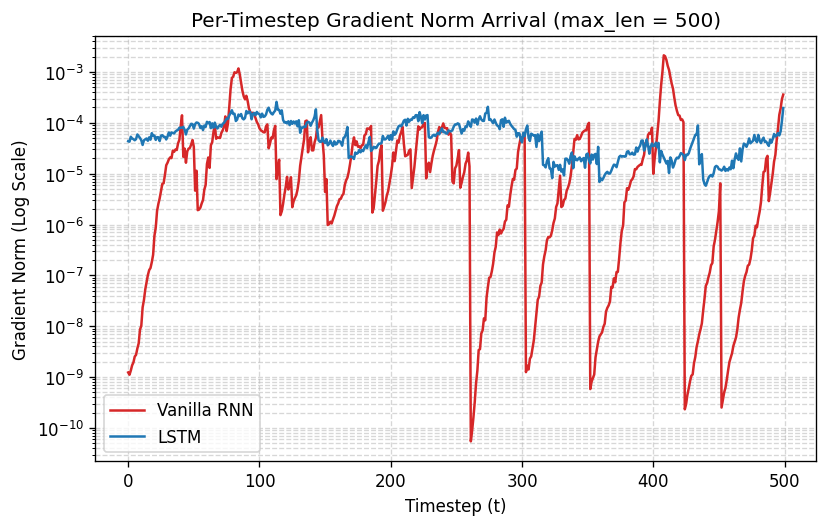

In [9]:
import json
import matplotlib.pyplot as plt
from pathlib import Path

rnn_path = Path("runs/q3/rnn_len500_h128/grad_norms.json")
lstm_path = Path("runs/q3/lstm_len500_h128/grad_norms.json")

if rnn_path.exists() and lstm_path.exists():
    rnn_data = json.loads(rnn_path.read_text())["rnn"]
    lstm_data = json.loads(lstm_path.read_text())["lstm"]

    plt.figure(figsize=(7, 4.5), dpi=120)
    plt.plot(rnn_data, label="Vanilla RNN", color="tab:red", linewidth=1.5)
    plt.plot(lstm_data, label="LSTM", color="tab:blue", linewidth=1.5)

    plt.yscale("log")
    plt.title("Per-Timestep Gradient Norm Arrival (max_len = 500)", fontsize=12)
    plt.xlabel("Timestep (t)", fontsize=10)
    plt.ylabel("Gradient Norm (Log Scale)", fontsize=10)
    plt.grid(True, which="both", linestyle="--", alpha=0.5)
    plt.legend()
    plt.tight_layout()
    plt.savefig("runs/q3/grad_norms_rnn_vs_lstm.png")
    plt.show()